In [1]:
%pip -q install datasets scikit-learn pandas numpy matplotlib seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


c:\Users\Oliver JR\Documents\INF8239_U02_NLP_Proyecto_Base\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import sys
print(sys.executable)

c:\Users\Oliver JR\Documents\INF8239_U02_NLP_Proyecto_Base\.venv\Scripts\python.exe


In [4]:
dataset = load_dataset("cardiffnlp/tweet_eval", "sentiment")
labels = ["negative", "neutral", "positive"]

c:\Users\Oliver JR\Documents\INF8239_U02_NLP_Proyecto_Base\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Oliver JR\.cache\huggingface\hub\datasets--cardiffnlp--tweet_eval. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\Oliver JR\Documents\INF8239_U02_NLP_Proyecto_Base\.venv\Lib\site-pa

In [6]:
train_df = dataset["train"].to_pandas()
valid_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

In [7]:
print(train_df.shape, valid_df.shape, test_df.shape)
print(train_df["label"].value_counts(normalize=True).sort_index())

(45615, 2) (2000, 2) (12284, 2)
label
0    0.155497
1    0.453206
2    0.391297
Name: proportion, dtype: float64


In [8]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=3,
        max_features=25_000
    )),
    ("classifier", LogisticRegression(
        max_iter=1_000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(train_df["text"], train_df["label"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",3
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",25000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


F1 macro validación: 0.6409956505285027
              precision    recall  f1-score   support

    negative      0.556     0.676     0.610      3972
     neutral      0.654     0.536     0.589      5937
    positive      0.546     0.594     0.569      2375

    accuracy                          0.593     12284
   macro avg      0.585     0.602     0.589     12284
weighted avg      0.601     0.593     0.592     12284



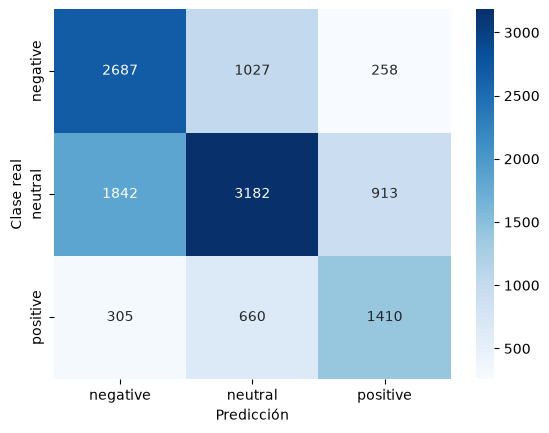

In [9]:
valid_pred = model.predict(valid_df["text"])
print("F1 macro validación:", f1_score(valid_df["label"], valid_pred, average="macro"))

test_pred = model.predict(test_df["text"])
print(classification_report(
    test_df["label"], test_pred,
    target_names=labels, digits=3
))

cm = confusion_matrix(test_df["label"], test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicción")
plt.ylabel("Clase real")
plt.show()

In [10]:
errors = test_df.copy()
errors["prediction"] = test_pred
errors = errors[errors["label"] != errors["prediction"]]
errors["real"] = errors["label"].map(dict(enumerate(labels)))
errors["predicted"] = errors["prediction"].map(dict(enumerate(labels)))
errors[["text", "real", "predicted"]].sample(20, random_state=42)

,text,real,predicted
9140,"With the most powerful binoculars, I cannot se...",neutral,positive
8021,@user The dividing lines that these new fascis...,negative,neutral
10816,@user #CapitalistArmy #MemeWars against libera...,negative,neutral
11987,How Medical Marijuana Could Combat the Opioid ...,neutral,negative
10374,2/2 #Yanukovich to #Ukraine ppl: @user give or...,neutral,negative
241,#Marijuana is medicine. 4 a very authoritative...,neutral,negative
3475,Vernon RCMP Cracking Down on Medical Marijuana...,neutral,negative
8541,Anyone else realised that getting a #Hatchimal...,neutral,negative
1217,Eat out and stay #Healthy. Yes. It is possible...,positive,neutral
4892,"Sodastream:.How to profit from Occupation, Opp...",neutral,negative


In [11]:
assert len(test_pred) == len(test_df)
assert set(np.unique(test_pred)).issubset({0, 1, 2})
assert "tfidf" in model.named_steps
assert "classifier" in model.named_steps
print("Verificaciones superadas")

Verificaciones superadas
